# WaZP Lensing Signals

Produce per-cluster ΔΣ data vectors for the WaZP "real-data" catalog built in `wazp_cluster_selection.ipynb`. Pipeline:

1. **Load WaZP real-data catalog** (§1) from `data/wazp_real_data.fits`.
2. **One-time pre-filter** of the 291 GB DES Y3 metacal HDF5 + 6 GB DNF photo-z HDF5 (§2). Apply the standard metacal cuts (`flags==0 & snr ∈ [10,1000] & size_ratio > 0.5 & T > 0`), require `zmean_sof > 0`, keep only the 10 columns `xlensing.data.metacal_cluster_lensing` needs, save to `data/metacal_filtered.npz`. Subsequent runs reload the intermediate.
3. **BallTree** over source (DEC, RA) in radians, haversine metric, for fast per-cluster cone queries (§3).
4. **Radial-bin layout** following the `prototype_destacking` convention (§4).
5. **Worker function** (§5): per cluster, query the cone, call `metacal_cluster_lensing`, package its output, call `single_cluster`, return `(sigmas, sigmas_cov, xigmas, xigmas_cov)`.
6. **Smoke-test on one cluster** (§6).
7. **`multiprocess.Pool`** over all WaZP clusters (§7).
8. **Save & sample plots** (§8).

Photo-z handling: the DNF file `DESY3_GOLD_2_2.1_DNF.h5` is row-aligned with metacal (same N = 399 263 026, same `coadd_object_id` ordering). We use `zmean_sof` as the per-source point estimate.

In [ ]:
import os, time, pickle, warnings
import numpy as np
import h5py
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.cosmology import Planck18 as COSMO
from astropy import units as u
from sklearn.neighbors import BallTree
from multiprocess import Pool, cpu_count
import xlensing.data
warnings.filterwarnings('ignore')

DATA          = '/mnt/c/Users/andre/DATA'
METACAL_FILE  = f'{DATA}/DESY3_metacal_v03-004.h5'
DNF_FILE      = f'{DATA}/DESY3_GOLD_2_2.1_DNF.h5'
# ── SIM/REAL toggle ───────────────────────────────────────────────────
SIMS          = True   # True to run on the simulated catalogue
SIM_PREFIX    = 'sim_g000'   # prefix for sim files (matches gen_sim_data_for_notebooks.py)

# Simulated per-run outputs live outside the repo (moved 2026-07-27, see
# project memory) -- real WaZP/DES-Y3 data stays under notebooks/data/.
SIM_DATA_DIR = os.path.expanduser('~/destacking_data/sims')

if SIMS:
    os.makedirs(SIM_DATA_DIR, exist_ok=True)
    WAZP_REAL    = f'{SIM_DATA_DIR}/{SIM_PREFIX}_real_data.fits'
    SIM_BGS_PKL  = f'{SIM_DATA_DIR}/{SIM_PREFIX}_bgs.pkl'
    RESULTS_PKL  = f'{SIM_DATA_DIR}/{SIM_PREFIX}_lensing_signals.pkl'
    FILTERED_NPZ = None   # not used in sim mode (bgs are pre-computed)
else:
    WAZP_REAL    = 'data/wazp_real_data.fits'
    SIM_BGS_PKL  = None
    RESULTS_PKL  = 'data/wazp_lensing_signals.pkl'
    FILTERED_NPZ = 'data/metacal_filtered.npz'

# Pipeline parameters --------------------------------------------------------
USE_CACHE  = False
# set to False to force a clean rebuild of every intermediate
RADIUS_MPC = 5.0           # Mpc, cone radius passed to metacal_cluster_lensing
NBOOT      = 200           # bootstrap resamplings for single_cluster cov
NWORKERS   = max(1, cpu_count() // 2)
CHUNK_READ = 10_000_000    # metacal rows per chunk during pre-filter

# Radial bins (Mpc), mirroring notebooks/prototype_destacking convention -----
radii  = np.logspace(-0.8, 0.6, 8)
_N     = len(radii)
_edges = np.logspace(
    np.log10(radii[0])   + (np.log10(radii[0]) - np.log10(radii[1])) / 2,
    np.log10(radii[-1])  - (np.log10(radii[0]) - np.log10(radii[1])) / 2,
    _N + 1,
)
BINS_LIMS = np.array([[_edges[i], _edges[i+1]] for i in range(_N)])

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
os.makedirs('data', exist_ok=True)

print(f'USE_CACHE  = {USE_CACHE}')
print(f'NWORKERS   = {NWORKERS}')
print(f'CHUNK_READ = {CHUNK_READ:,}')
print(f'RADIUS_MPC = {RADIUS_MPC}')
print(f'NBOOT      = {NBOOT}')
print(f'Radial bin centres (Mpc): {np.round(radii, 3)}')

## 1 — Load the WaZP real-data catalog

In [2]:
wazp_all = Table.read(WAZP_REAL)
print(f'Loaded {len(wazp_all):,} clusters from {WAZP_REAL}')

# Same selection as wazp_mass_richness_by_delta_m: drop clusters with
# non-finite or non-positive DELTA_M_I — these are cluster-finder
# artefacts where the catalog's BCG is fainter than the brightest
# inner satellite.  Upstream wazp_cluster_selection already imposed
# NGALS > 25, ZPHOT < 0.7, and BCG-present.
keep = np.isfinite(wazp_all['DELTA_M_I']) & (wazp_all['DELTA_M_I'] > 0)
wazp = wazp_all[keep]
print(f'After Δm > 0 cut: {len(wazp):,}  '
      f'(dropped {len(wazp_all) - len(wazp):,})')
print(f'Columns: {wazp.colnames}')
print(wazp[:5])


Loaded 15,000 clusters from data/sim_g000_real_data.fits
After Δm > 0 cut: 15,000  (dropped 0)
Columns: ['ID', 'RA', 'DEC', 'NGALS', 'ZPHOT', 'DELTA_M_I', 'DELTA_M_I_ERR']
 ID  RA   DEC    NGALS     ZPHOT     DELTA_M_I  DELTA_M_I_ERR
--- ---- ----- --------- ---------- ----------- -------------
  0 10.0 -60.0  32.46713  0.3559108  0.09712192          0.01
  1 10.6 -60.0    68.345 0.57523185 0.010389394          0.01
  2 11.2 -60.0  45.20324  0.5743247  0.01797985          0.01
  3 11.8 -60.0 28.091082 0.25591573 0.014313453          0.01
  4 12.4 -60.0 36.571514  0.3116632 0.060904514          0.01


## 2 — One-time pre-filter of the metacal + DNF catalogs

Streams both HDF5 files in `CHUNK_READ`-row chunks, applies the standard metacal selection plus `zmean_sof > 0`, and keeps only the 10 columns that `metacal_cluster_lensing` consumes. Saves to `data/metacal_filtered.npz` so re-runs skip this step.

Row alignment is verified up-front via the first/last `coadd_object_id` in each file.

In [3]:
if SIMS:
    print(f'SIMS=True: skipping metacal pre-filter; per-cluster bgs come from {SIM_BGS_PKL}')
    SR_RA = SR_DEC = SR_Z = SR_E1 = SR_E2 = SR_W = None
    SR_R11 = SR_R12 = SR_R21 = SR_R22 = None
elif os.path.exists(FILTERED_NPZ) and USE_CACHE:
    print(f'Loading cached pre-filter from {FILTERED_NPZ}...')
    f = np.load(FILTERED_NPZ)
    SR_RA  = f['ra']
    SR_DEC = f['dec']
    SR_Z   = f['z']
    SR_E1  = f['e1']
    SR_E2  = f['e2']
    SR_W   = f['w']
    SR_R11 = f['R11']
    SR_R12 = f['R12']
    SR_R21 = f['R21']
    SR_R22 = f['R22']
    print(f'Loaded {len(SR_RA):,} pre-filtered sources')
else:
    if os.path.exists(FILTERED_NPZ):
        print(f'USE_CACHE = False, rebuilding {FILTERED_NPZ} from scratch')
    print(f'Building pre-filter from {METACAL_FILE} + {DNF_FILE} ...')
    cols = {k: [] for k in ['ra','dec','z','e1','e2','w',
                            'R11','R12','R21','R22']}
    with h5py.File(METACAL_FILE, 'r') as fm, h5py.File(DNF_FILE, 'r') as fz:
        g  = fm['catalog/unsheared']
        gz = fz['catalog/unsheared']
        Ntot = g['ra'].shape[0]
        assert Ntot == gz['zmean_sof'].shape[0], 'Row count mismatch'
        assert int(g['coadd_object_id'][0])      == int(gz['coadd_object_id'][0])
        assert int(g['coadd_object_id'][Ntot-1]) == int(gz['coadd_object_id'][Ntot-1])

        t0 = time.time()
        for s in range(0, Ntot, CHUNK_READ):
            e = min(s + CHUNK_READ, Ntot)

            flags = g['flags'][s:e]
            snr   = g['snr'][s:e]
            sr    = g['size_ratio'][s:e]
            T     = g['T'][s:e]
            zmean = gz['zmean_sof'][s:e]

            sel = ((flags == 0) & (snr > 10) & (snr < 1000)
                   & (sr > 0.5) & (T > 0) & (zmean > 0))
            if not sel.any():
                continue
            idx = np.where(sel)[0]

            cols['ra' ].append(np.deg2rad(g['ra' ][s:e][idx]).astype('float64'))
            cols['dec'].append(np.deg2rad(g['dec'][s:e][idx]).astype('float64'))
            cols['z'  ].append(zmean[idx].astype('float32'))
            cols['e1' ].append(g['e_1'][s:e][idx].astype('float32'))
            cols['e2' ].append(g['e_2'][s:e][idx].astype('float32'))
            cols['w'  ].append(g['weight'][s:e][idx].astype('float32'))
            cols['R11'].append(g['R11'][s:e][idx].astype('float32'))
            cols['R12'].append(g['R12'][s:e][idx].astype('float32'))
            cols['R21'].append(g['R21'][s:e][idx].astype('float32'))
            cols['R22'].append(g['R22'][s:e][idx].astype('float32'))

            dt   = time.time() - t0
            kept = sum(len(x) for x in cols['ra'])
            eta  = dt * (Ntot - e) / max(e, 1)
            print(f'  {e:>11,}/{Ntot:,}  kept {kept:>11,}  '
                  f'elapsed {dt:6.1f}s  eta {eta:6.1f}s', flush=True)

    print('Concatenating per-chunk buffers ...')
    cols = {k: np.concatenate(v) for k, v in cols.items()}
    print(f'Total kept: {len(cols["ra"]):,}')

    print(f'Writing {FILTERED_NPZ} ...')
    np.savez(FILTERED_NPZ,
        ra=cols['ra'], dec=cols['dec'], z=cols['z'],
        e1=cols['e1'], e2=cols['e2'], w =cols['w'],
        R11=cols['R11'], R12=cols['R12'],
        R21=cols['R21'], R22=cols['R22'],
    )
    SR_RA  = cols['ra'];  SR_DEC = cols['dec']; SR_Z = cols['z']
    SR_E1  = cols['e1'];  SR_E2  = cols['e2'];  SR_W = cols['w']
    SR_R11 = cols['R11']; SR_R12 = cols['R12']
    SR_R21 = cols['R21']; SR_R22 = cols['R22']
    print('Done.')

if not SIMS:
    print()
    print(f'Source count: {len(SR_RA):,}')
    print(f'RA range  (rad): {SR_RA.min():.3f} to {SR_RA.max():.3f}')
    print(f'DEC range (rad): {SR_DEC.min():.3f} to {SR_DEC.max():.3f}')
    print(f'z range        : {SR_Z.min():.3f} to {SR_Z.max():.3f}')


SIMS=True: skipping metacal pre-filter; per-cluster bgs come from data/sim_g000_bgs.pkl


## 3 — BallTree spatial index

`sklearn.neighbors.BallTree` with the haversine metric expects positions as `(lat, lon) = (dec, ra)` in radians. The tree is built once in the parent process; child workers inherit it through `fork()`.

In [4]:
if SIMS:
    print('SIMS=True: skipping BallTree build (bgs are pre-computed per cluster)')
    SIM_BGS_BY_ID = pickle.load(open(SIM_BGS_PKL, 'rb'))
    print(f'Loaded {len(SIM_BGS_BY_ID):,} per-cluster bgs from {SIM_BGS_PKL}')
    TREE = None
else:
    t0 = time.time()
    positions = np.column_stack([SR_DEC, SR_RA])
    TREE = BallTree(positions, metric='haversine')
    print(f'BallTree built over {len(positions):,} sources in {time.time()-t0:.1f}s')
    SIM_BGS_BY_ID = None


SIMS=True: skipping BallTree build (bgs are pre-computed per cluster)
Loaded 15,000 per-cluster bgs from data/sim_g000_bgs.pkl


## 4 — Radial bins

In [5]:
print('Radial bin layout (Mpc, proper):')
for i, (lo, hi) in enumerate(BINS_LIMS):
    print(f'  bin {i}: [{lo:.3f}, {hi:.3f}]  centre = {radii[i]:.3f}')

Radial bin layout (Mpc, proper):
  bin 0: [0.126, 0.200]  centre = 0.158
  bin 1: [0.200, 0.316]  centre = 0.251
  bin 2: [0.316, 0.501]  centre = 0.398
  bin 3: [0.501, 0.794]  centre = 0.631
  bin 4: [0.794, 1.259]  centre = 1.000
  bin 5: [1.259, 1.995]  centre = 1.585
  bin 6: [1.995, 3.162]  centre = 2.512
  bin 7: [3.162, 5.012]  centre = 3.981


## 5 — Per-cluster worker

For each cluster:
1. Compute the worst-case angular cone radius `RADIUS_MPC / D_A(z_cl)`.
2. Query the BallTree for source indices inside that cone.
3. Build the 10-tuple in the order `metacal_cluster_lensing` expects (`(ra, dec, z, e1, e2, w, R11, R12, R21, R22)`, RA/DEC in radians).
4. Run `metacal_cluster_lensing` → repackage to the 6-row array shape that `single_cluster` expects → run `single_cluster([bkg], BINS_LIMS, NBOOT)`.

Source arrays and the BallTree live as module-level globals so forked workers inherit them via copy-on-write — no per-worker pickling cost.

In [6]:
def cluster_worker(row):
    """row: dict with keys 'ID', 'RA' (deg), 'DEC' (deg), 'ZPHOT'.
    When SIMS=True, bg is loaded from the pre-computed SIM_BGS_BY_ID dict;
    otherwise it is constructed on the fly from a BallTree cone query."""
    try:
        cid   = int(row['ID'])
        z_cl  = float(row['ZPHOT'])

        if SIMS:
            bkg = SIM_BGS_BY_ID.get(cid)
            if bkg is None:
                return {'ID': cid, 'sigmas': None, 'count': 0}
            count = int(bkg.shape[1])
        else:
            ra_r  = np.deg2rad(float(row['RA']))
            dec_r = np.deg2rad(float(row['DEC']))
            D_A   = float(COSMO.angular_diameter_distance(z_cl).to_value(u.Mpc))
            if D_A <= 0:
                return {'ID': cid, 'error': f'D_A={D_A}'}
            ang_r = RADIUS_MPC / D_A
            idx = TREE.query_radius(np.array([[dec_r, ra_r]]), r=ang_r)[0]
            if len(idx) == 0:
                return {'ID': cid, 'sigmas': None, 'count': 0}
            sources = (
                SR_RA [idx], SR_DEC[idx], SR_Z [idx],
                SR_E1 [idx], SR_E2 [idx], SR_W [idx],
                SR_R11[idx], SR_R12[idx], SR_R21[idx], SR_R22[idx],
            )
            cluster = (ra_r, dec_r, z_cl)
            res = xlensing.data.metacal_cluster_lensing(
                cluster, sources, radius=RADIUS_MPC,
            )
            if res['Count'] == 0:
                return {'ID': cid, 'sigmas': None, 'count': 0}
            bkg = np.array([
                np.asarray(res['Critical Density']),
                np.asarray(res['Tangential Shear']),
                np.asarray(res['Cross Shear']),
                np.asarray(res['Weights']),
                np.asarray(res['Radial Distance']),
                np.asarray(res['Mult. Bias']),
            ])
            count = int(res['Count'])

        sigmas, boosts, boosts_cov, sigmas_cov, xigmas, xigmas_cov = (
            xlensing.data.single_cluster([bkg], BINS_LIMS, NBOOT)
        )
        return {
            'ID':         cid,
            'sigmas':     np.asarray(sigmas),
            'sigmas_cov': np.asarray(sigmas_cov),
            'boosts':     np.asarray(boosts),
            'boosts_cov': np.asarray(boosts_cov),
            'xigmas':     np.asarray(xigmas),
            'xigmas_cov': np.asarray(xigmas_cov),
            'count':      count,
        }
    except Exception as exc:
        return {'ID': int(row.get('ID', -1)), 'error': repr(exc)}


## 6 — Smoke-test on a single cluster

Run one cluster serially before launching the pool to verify the pipeline end-to-end.

In [7]:
row0 = {'ID': int(wazp['ID'][0]),  'RA': float(wazp['RA'][0]),
        'DEC': float(wazp['DEC'][0]), 'ZPHOT': float(wazp['ZPHOT'][0])}
t0 = time.time()
r0 = cluster_worker(row0)
dt = time.time() - t0
print(f'One cluster in {dt:.2f}s -> keys = {list(r0.keys())}')
if 'sigmas' in r0 and r0['sigmas'] is not None:
    print(f'  ΔΣ            = {r0["sigmas"]}')
    print(f'  diag σ_ΔΣ     = {np.sqrt(np.diag(r0["sigmas_cov"]))}')
    print(f'  boost B(R)    = {r0["boosts"]}')
    print(f'  diag σ_B(R)   = {np.sqrt(np.diag(r0["boosts_cov"]))}')
    print(f'  N srcs in cone = {r0["count"]}')


Total galaxies available per bin:
[0, 0, 4, 17, 26, 71, 164, 419]

One cluster in 0.03s -> keys = ['ID', 'sigmas', 'sigmas_cov', 'boosts', 'boosts_cov', 'xigmas', 'xigmas_cov', 'count']
  ΔΣ            = [nan nan nan nan nan nan nan nan]
  diag σ_ΔΣ     = [nan nan nan nan nan nan nan nan]
  boost B(R)    = [0.         0.         1.35416667 1.12633333 1.07645833 1.06962687
 0.98137725 0.96901392]
  diag σ_B(R)   = [0.         0.         0.70122058 0.24686963 0.2039436  0.10981408
 0.06591828 0.03780095]
  N srcs in cone = 1168


## 7 — Parallel run over all WaZP clusters

Linux fork lets each worker share the `SR_*` arrays and `TREE` read-only via COW, so there's no per-task pickling cost for the catalog. We use `imap_unordered` with a small `chunksize` so progress is visible and a slow cluster doesn't stall a batch.

In [8]:
input_list = [
    {'ID': int(wazp['ID'][i]),    'RA':   float(wazp['RA'][i]),
     'DEC':float(wazp['DEC'][i]), 'ZPHOT':float(wazp['ZPHOT'][i])}
    for i in range(len(wazp))
]
print(f'Submitting {len(input_list):,} clusters to a pool of {NWORKERS} workers')

results = []
CKPT_EVERY = 1000
t0 = time.time()
with Pool(NWORKERS) as pool:
    for i, r in enumerate(pool.imap_unordered(
            cluster_worker, input_list, chunksize=4)):
        results.append(r)
        if (i + 1) % 200 == 0 or (i + 1) == len(input_list):
            dt  = time.time() - t0
            eta = dt * (len(input_list) - i - 1) / (i + 1)
            print(f'  {i+1:>6,}/{len(input_list):,}  '
                  f'elapsed {dt/60:5.1f} min  eta {eta/60:5.1f} min',
                  flush=True)
        if (i + 1) % CKPT_EVERY == 0:
            with open(RESULTS_PKL + '.partial', 'wb') as fh:
                pickle.dump(results, fh)

print(f'\nDone in {(time.time()-t0)/60:.1f} min, {len(results):,} results.')

Submitting 15,000 clusters to a pool of 8 workers
Total galaxies available per bin:Total galaxies available per bin:Total galaxies available per bin:
Total galaxies available per bin:
Total galaxies available per bin:Total galaxies available per bin:Total galaxies available per bin:[4, 7, 13, 27, 57, 151, 431, 913]Total galaxies available per bin:


[0, 0, 4, 17, 26, 71, 164, 419][0, 1, 2, 5, 9, 19, 61, 120]
[3, 6, 14, 36, 91, 219, 607, 783]



[0, 0, 2, 4, 7, 26, 62, 132][0, 6, 4, 23, 37, 97, 215, 568][1, 1, 5, 17, 38, 69, 223, 530]

[0, 0, 3, 2, 11, 21, 61, 154]











Total galaxies available per bin:
Total galaxies available per bin:[1, 0, 5, 6, 12, 37, 64, 185]

Total galaxies available per bin:[2, 1, 11, 23, 86, 168, 409, 951]



[0, 1, 0, 6, 7, 21, 41, 115]

Total galaxies available per bin:Total galaxies available per bin:
Total galaxies available per bin:Total galaxies available per bin:

[3, 7, 25, 48, 140, 378, 968, 322][2, 2, 3, 4, 23, 41, 133, 293]Total galaxies availa

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)





Total galaxies available per bin:


Total galaxies available per bin:
[1, 2, 4, 13, 32, 84, 208, 471]
[8, 17, 51, 110, 241, 705, 945, 0]
[0, 0, 0, 5, 4, 13, 44, 85]

[0, 0, 0, 0, 8, 14, 44, 96]




Total galaxies available per bin:

[0, 3, 6, 8, 30, 67, 183, 417]Total galaxies available per bin:


Total galaxies available per bin:Total galaxies available per bin:[0, 2, 6, 14, 36, 84, 184, 470]Total galaxies available per bin:



[0, 2, 0, 9, 10, 27, 70, 164][0, 2, 6, 9, 20, 54, 134, 313][0, 0, 0, 3, 13, 18, 39, 122]






Total galaxies available per bin:
Total galaxies available per bin:Total galaxies available per bin:[2, 1, 6, 14, 46, 140, 271, 814]

Total galaxies available per bin:
Total galaxies available per bin:[1, 6, 9, 20, 35, 92, 203, 555][0, 2, 3, 9, 12, 41, 79, 192]
Total galaxies available per bin:




[0, 2, 3, 8, 12, 22, 82, 218]
[0, 1, 2, 11, 33, 81, 221, 540]

[2, 3, 5, 11, 51, 117, 293, 760]


Total galaxies available per bin:


[0, 3, 1, 7, 14, 47, 107, 245]Total 

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



Total galaxies available per bin:




[1, 3, 8, 19, 28, 105, 241, 538]

[1, 4, 4, 20, 46, 109, 250, 638]



Total galaxies available per bin:Total galaxies available per bin:
[0, 0, 2, 4, 11, 25, 58, 133]
Total galaxies available per bin:
[0, 0, 1, 3, 6, 17, 46, 116]Total galaxies available per bin:



Total galaxies available per bin:Total galaxies available per bin:
Total galaxies available per bin:
Total galaxies available per bin:[3, 12, 33, 58, 196, 471, 1214, 0][1, 0, 4, 11, 16, 55, 113, 252]

[0, 1, 1, 1, 4, 18, 35, 118]





[5, 10, 28, 62, 183, 451, 1052, 149][1, 2, 15, 30, 59, 181, 457, 950]Total galaxies available per bin:

Total galaxies available per bin:

[0, 0, 0, 6, 3, 14, 43, 81]

Total galaxies available per bin:[0, 3, 10, 29, 77, 143, 437, 898]

[10, 24, 63, 147, 355, 920, 685, 0]
Total galaxies available per bin:Total galaxies available per bin:





[0, 3, 10, 14, 41, 90, 250, 643]
Total galaxies available per bin:[2, 1, 3, 11, 35, 77, 183, 472]
[1, 0, 1, 8, 10, 24

...

[0, 6, 11, 39, 96, 288, 579, 698][0, 2, 12, 12, 37, 105, 254, 620]




Total galaxies available per bin:

[0, 0, 1, 4, 11, 17, 44, 140]

Total galaxies available per bin:Total galaxies available per bin:

Total galaxies available per bin:[1, 0, 2, 8, 12, 37, 71, 233]Total galaxies available per bin:[2, 6, 9, 34, 73, 184, 480, 847]



[1, 3, 2, 6, 19, 61, 123, 336]


[0, 1, 0, 9, 13, 30, 69, 213]Total galaxies available per bin:

Total galaxies available per bin:


[0, 1, 2, 4, 9, 26, 57, 125][2, 4, 6, 21, 35, 84, 180, 479]

Total galaxies available per bin:


Total galaxies available per bin:[0, 0, 1, 0, 10, 22, 36, 102]

Total galaxies available per bin:
[0, 1, 4, 4, 10, 28, 94, 181]Total galaxies available per bin:

[7, 18, 43, 105, 274, 641, 1012, 0]

Total galaxies available per bin:
[0, 4, 12, 33, 70, 173, 470, 964]

Total galaxies available per bin:[2, 3, 14, 37, 105, 250, 582, 779]
Total galaxies available per bin:[0, 0, 1, 2, 13, 30, 72, 190]





[0, 3, 2, 13, 41, 77, 239, 490

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)




[0, 3, 3, 15, 33, 69, 221, 496]
Total galaxies available per bin:
Total galaxies available per bin:[2, 4, 11, 41, 91, 237, 559, 808]
Total galaxies available per bin:





[0, 0, 6, 5, 21, 39, 84, 227][1, 1, 1, 7, 15, 32, 91, 197][2, 1, 2, 9, 27, 60, 207, 434]


Total galaxies available per bin:
Total galaxies available per bin:


[0, 4, 5, 20, 48, 118, 272, 756]

Total galaxies available per bin:Total galaxies available per bin:[1, 0, 4, 6, 17, 29, 88, 275]

Total galaxies available per bin:
[0, 4, 7, 19, 31, 98, 228, 584]
Total galaxies available per bin:
Total galaxies available per bin:[0, 0, 1, 3, 9, 13, 40, 123]



[1, 6, 22, 34, 92, 286, 658, 706][0, 2, 9, 12, 36, 89, 219, 560][1, 5, 24, 44, 112, 293, 708, 636]






Total galaxies available per bin:Total galaxies available per bin:



[1, 0, 2, 12, 17, 51, 124, 335][1, 0, 4, 6, 11, 27, 78, 124]



Total galaxies available per bin:Total galaxies available per bin:

Total galaxies available per bin:Total galaxies available per b

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)




Total galaxies available per bin:
Total galaxies available per bin:[0, 0, 2, 2, 11, 19, 29, 94]
[0, 1, 1, 5, 15, 17, 55, 194]

[2, 3, 18, 25, 87, 219, 591, 875]
Total galaxies available per bin:Total galaxies available per bin:


[3, 11, 23, 67, 159, 372, 858, 369]
Total galaxies available per bin:

Total galaxies available per bin:
[0, 1, 3, 2, 7, 22, 56, 126]Total galaxies available per bin:

[0, 0, 3, 5, 19, 30, 97, 266]
[0, 1, 2, 6, 6, 26, 63, 138]
[2, 3, 24, 53, 113, 327, 710, 576]



Total galaxies available per bin:



Total galaxies available per bin:Total galaxies available per bin:Total galaxies available per bin:Total galaxies available per bin:

[0, 2, 9, 15, 47, 105, 241, 667]Total galaxies available per bin:[2, 4, 9, 29, 93, 233, 559, 831]Total galaxies available per bin:



[0, 2, 3, 9, 27, 51, 133, 342]
[0, 3, 0, 5, 16, 29, 88, 196]
[0, 1, 2, 0, 9, 23, 43, 122]

[0, 0, 2, 2, 12, 29, 91, 186]

[4, 3, 9, 17, 40, 76, 225, 519]
Total galaxies available per bin:






[0, 1

## 8 — Save results & sample profiles

In [9]:
with open(RESULTS_PKL, 'wb') as fh:
    pickle.dump({'radii': radii, 'bins_lims': BINS_LIMS,
                 'nboot': NBOOT, 'radius_mpc': RADIUS_MPC,
                 'selection': 'wazp_real_data + DELTA_M_I > 0',
                 'results': results}, fh)
print(f'Wrote {len(results):,} results to {RESULTS_PKL}')

errs   = [r for r in results if 'error'  in r]
empty  = [r for r in results if r.get('sigmas') is None]
good   = [r for r in results if r.get('sigmas') is not None]
print(f'  good profiles : {len(good):,}')
print(f'  empty (no src): {len(empty):,}')
print(f'  errors        : {len(errs):,}')
for r in errs[:3]:
    print('   ', r)

# Outer-bin boost should fall near 1 if the field background dominates.
if good:
    b_outer = np.array([r['boosts'][-1] for r in good])
    print(f'\nOuter-bin boost over {len(good):,} clusters:')
    print(f'  median = {np.median(b_outer):.3f}  mean = {b_outer.mean():.3f}  '
          f'std = {b_outer.std():.3f}')


Wrote 15,000 results to data/sim_g000_lensing_signals.pkl
  good profiles : 15,000
  empty (no src): 0
  errors        : 0

Outer-bin boost over 15,000 clusters:
  median = 0.980  mean = 0.884  std = 0.282


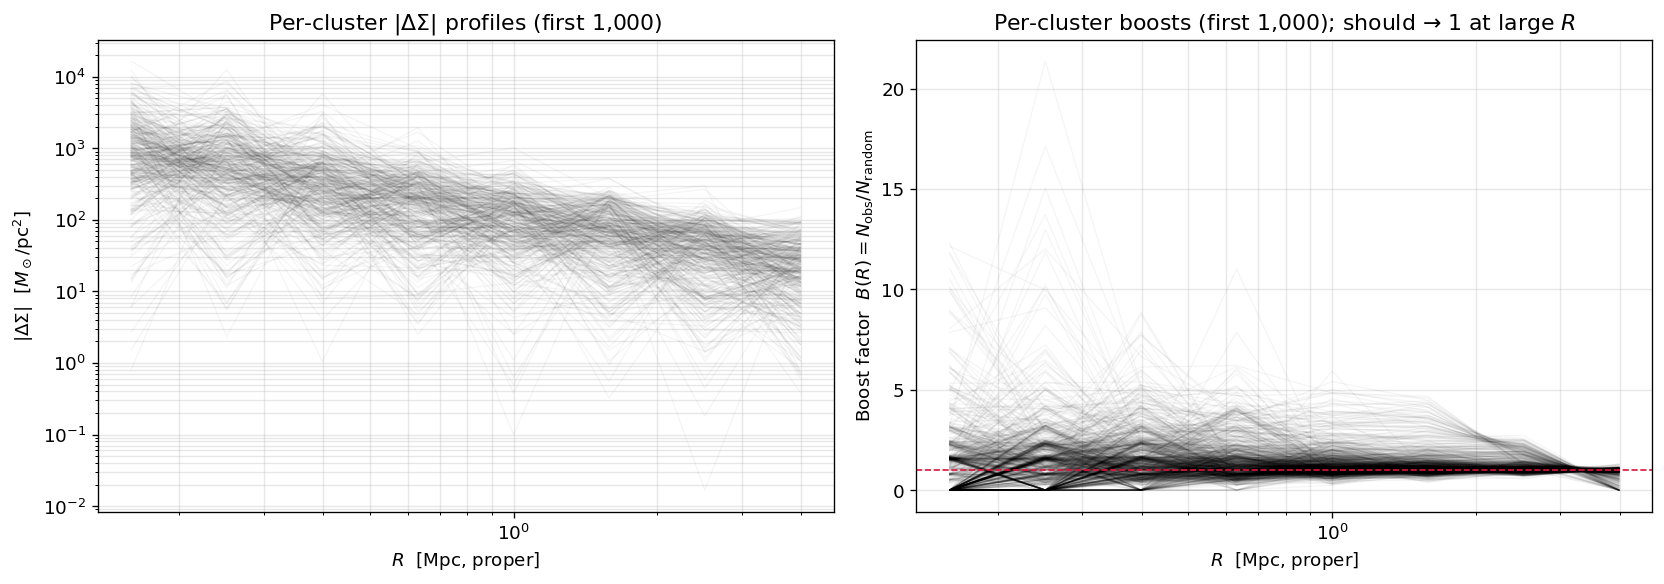

In [10]:
# Side-by-side: per-cluster ΔΣ profiles and per-cluster boost factors.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── ΔΣ ───────────────────────────────────────────────────────────────────
ax = axes[0]
for r in good[:1000]:
    ax.plot(radii, np.abs(r['sigmas']), color='k', alpha=0.04, lw=0.8)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$R$  [Mpc, proper]')
ax.set_ylabel(r'$|\Delta\Sigma|$  [$M_\odot/\mathrm{pc}^2$]')
ax.set_title(f'Per-cluster $|\Delta\Sigma|$ profiles (first {min(1000, len(good)):,})')
ax.grid(alpha=0.3, which='both')

# ── boost ────────────────────────────────────────────────────────────────
ax = axes[1]
for r in good[:1000]:
    ax.plot(radii, r['boosts'], color='k', alpha=0.04, lw=0.8)
ax.axhline(1.0, color='crimson', lw=1.0, ls='--')
ax.set_xscale('log')
ax.set_xlabel(r'$R$  [Mpc, proper]')
ax.set_ylabel(r'Boost factor  $B(R) = N_{\rm obs}/N_{\rm random}$')
ax.set_title(f'Per-cluster boosts (first {min(1000, len(good)):,}); should → 1 at large $R$')
ax.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()


## 9 — Per-cluster average vs stacked ΔΣ — relative residual

Re-use the (z, NGALS, Δm) stack definition from `wazp_mass_richness_by_delta_m` (loaded from `data/wazp_mr_dm_stacks.pkl`).  For each stack, compute the **inverse-variance-weighted mean** of the boost-corrected per-cluster ΔΣ profiles measured in this notebook and compare it to the boost-corrected stacked ΔΣ from the mass-richness pickle.  Both sides keep the canonical boost factor applied.

Plot

$$
\frac{\langle\Delta\Sigma\rangle_{\rm ind}(R) - \Delta\Sigma_{\rm stack}(R)}{\Delta\Sigma_{\rm stack}(R)}\,\times\,100\,\%
$$

against $R$ for every (z, λ, Δm) stack — same residual convention as the triaxiality tests.  The stacked signal lives on a finer 18-bin grid than this notebook's 8-bin radii, so it is linearly interpolated in $\log_{10} R$ onto this notebook's `radii` before differencing.

Optional low-boost filter (`MIN_BOOST_INCLUDE`): drop per-cluster contributions where the cluster's own boost falls below the threshold in any bin — proxy for clusters too sparse in inner radii to estimate the per-cluster boost reliably.  Set to `0.0` to keep every cluster (default).

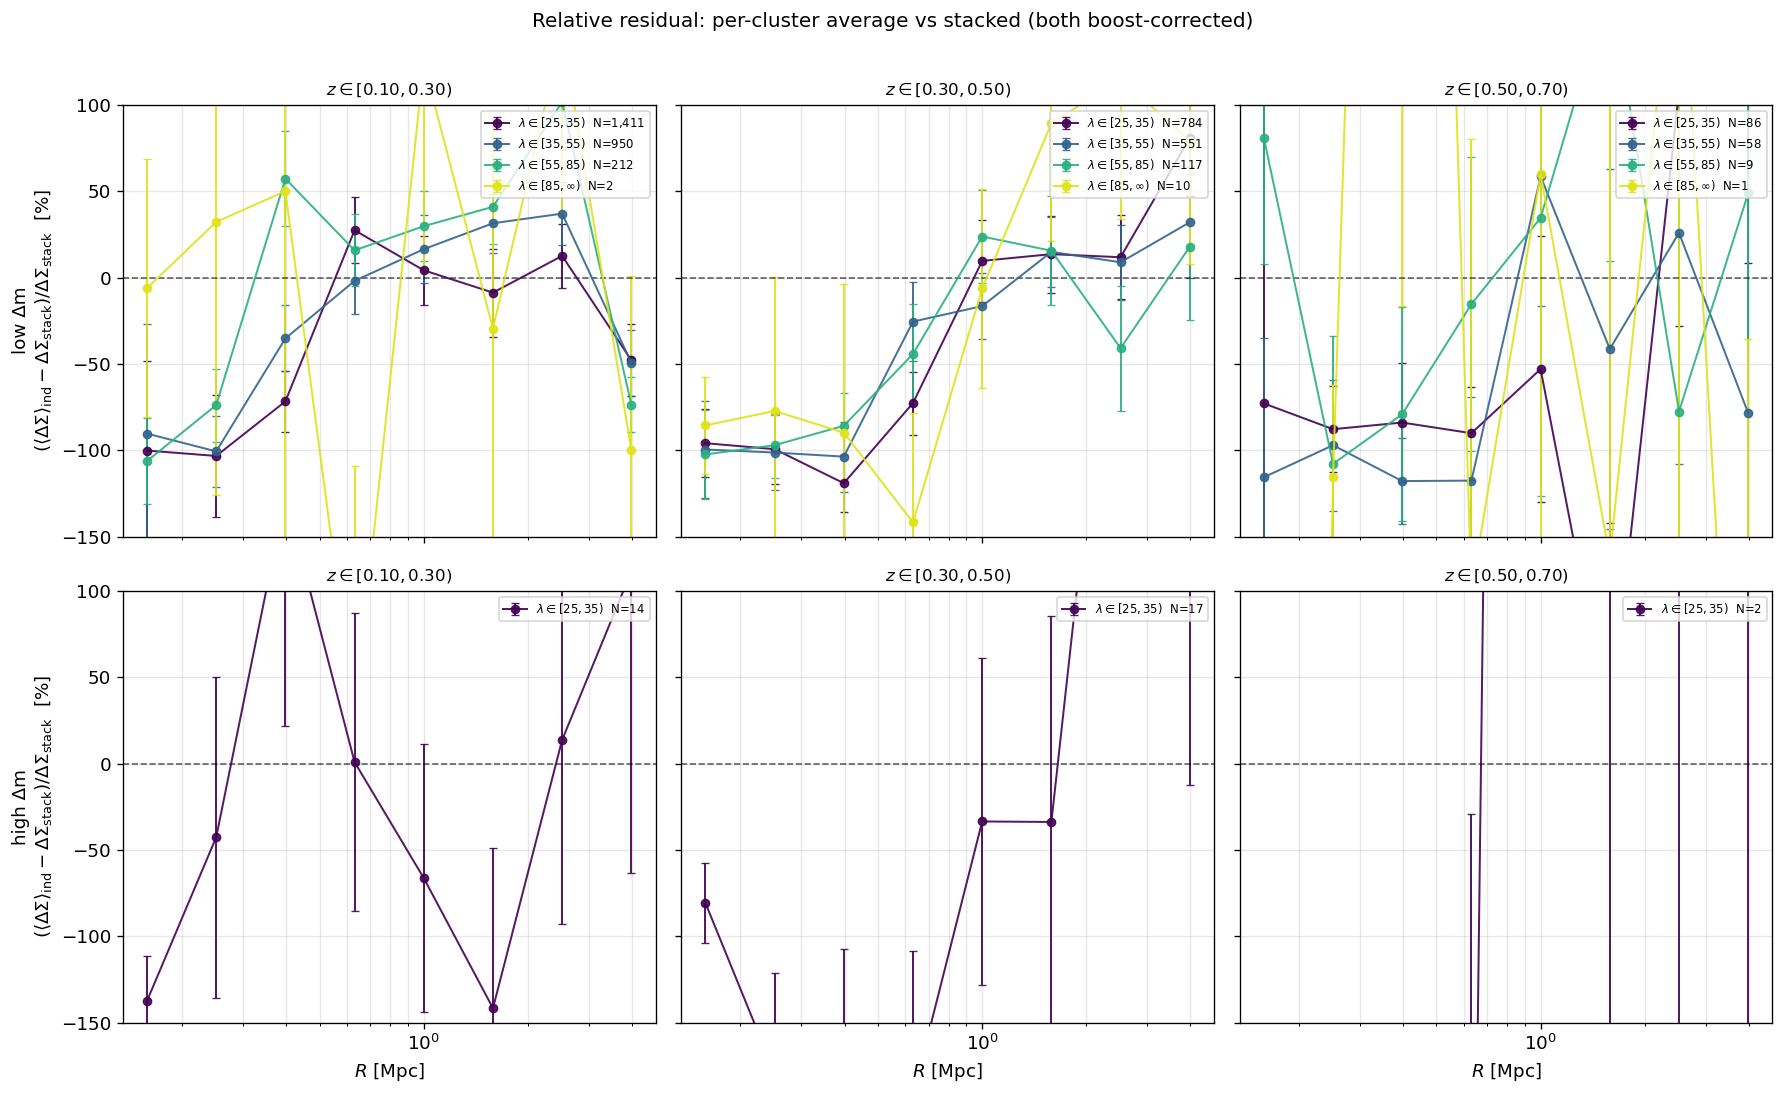

In [11]:
STACKS_PKL_MR      = 'data/wazp_mr_dm_stacks.pkl'
MIN_BOOST_INCLUDE  = 0.0   # raise (e.g. 0.5) to drop sparse-inner-bin clusters

if not os.path.exists(STACKS_PKL_MR):
    print(f'{STACKS_PKL_MR} not found; run wazp_mass_richness_by_delta_m first.')
else:
    with open(STACKS_PKL_MR, 'rb') as fh:
        stk_data = pickle.load(fh)
    mr_radii   = np.asarray(stk_data['radii'])
    z_edges    = stk_data['z_edges']
    ng_edges   = stk_data['ng_edges']
    dm_medians = stk_data['dm_median_per_cell']
    stacks     = stk_data['stacks']
    N_NG       = len(ng_edges) - 1

    def _bin_idx(values, edges):
        v   = np.asarray(values, dtype=float)
        idx = np.digitize(v, edges[1:-1], right=False)
        out = ~((v >= edges[0]) & (v <= edges[-1]))
        idx[out] = -1
        return idx
    z_bin_arr  = _bin_idx(wazp['ZPHOT'], z_edges)
    ng_bin_arr = _bin_idx(wazp['NGALS'], ng_edges)
    dm_bin_arr = np.full(len(wazp), -1, dtype=int)
    for (ii, jj), med in dm_medians.items():
        if med is None: continue
        cell = (z_bin_arr == ii) & (ng_bin_arr == jj)
        cell_dm  = np.asarray(wazp['DELTA_M_I'])[cell]
        glob_idx = np.where(cell)[0]
        dm_bin_arr[glob_idx[cell_dm <  med]] = 0
        dm_bin_arr[glob_idx[cell_dm >= med]] = 1

    good_by_id = {r['ID']: r for r in good}

    def avg_per_stack(ii, jj, kk):
        """Per-stack inverse-variance-weighted mean of the boost-corrected
        per-cluster ΔΣ (the canonical single_cluster output).  Clusters
        whose per-cluster boost drops below MIN_BOOST_INCLUDE in any bin
        are dropped — proxy for too few inner-bin galaxies."""
        mask = (z_bin_arr == ii) & (ng_bin_arr == jj) & (dm_bin_arr == kk)
        ids  = np.asarray(wazp['ID'])[mask]
        sigs, vars_d = [], []
        n_dropped = 0
        for cid in ids:
            r = good_by_id.get(int(cid))
            if r is None: continue
            s = np.asarray(r['sigmas'],     dtype=float)
            b = np.asarray(r['boosts'],     dtype=float)
            v = np.diag(np.asarray(r['sigmas_cov'], dtype=float))
            ok = np.isfinite(s) & np.isfinite(v) & (v > 0)
            if not ok.all(): continue
            if MIN_BOOST_INCLUDE > 0 and (b < MIN_BOOST_INCLUDE).any():
                n_dropped += 1
                continue
            sigs.append(s)
            vars_d.append(v)
        if not sigs:
            return None
        sigs   = np.asarray(sigs)
        vars_d = np.asarray(vars_d)
        w = 1.0 / vars_d
        mean = (sigs * w).sum(axis=0) / w.sum(axis=0)
        err  = np.sqrt(1.0 / w.sum(axis=0))
        return mean, err, len(sigs), n_dropped

    def interp_to_radii(stk_sig, stk_err, target):
        """Linear interpolation of stacked sigmas and errors in log10 R."""
        log_mr = np.log10(mr_radii)
        log_tg = np.log10(target)
        valid  = np.isfinite(stk_sig) & np.isfinite(stk_err)
        sig_i  = np.interp(log_tg, log_mr[valid], stk_sig[valid],
                            left=np.nan, right=np.nan)
        err_i  = np.interp(log_tg, log_mr[valid], stk_err[valid],
                            left=np.nan, right=np.nan)
        return sig_i, err_i

    ng_colors = [plt.cm.viridis(x) for x in np.linspace(0.0, 0.95, N_NG)]
    dm_titles = {0: 'low Δm', 1: 'high Δm'}

    fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
    drop_log = []
    for kk in range(2):
        for ii in range(3):
            ax = axes[kk, ii]
            for jj in range(N_NG):
                name = f'z{ii}_ng{jj}_dm{kk}'
                if name not in stacks: continue
                s_stk    = stacks[name]
                stk_sig  = np.asarray(s_stk['sigmas'])     # boost-corrected
                stk_err  = np.sqrt(np.diag(np.asarray(s_stk['sigmas_cov'])))

                grp = avg_per_stack(ii, jj, kk)
                if grp is None: continue
                mean_ind, sig_ind, Nused, n_dropped = grp
                drop_log.append((name, Nused, n_dropped))

                stk_at_r, stk_err_at_r = interp_to_radii(stk_sig, stk_err, radii)

                with np.errstate(divide='ignore', invalid='ignore'):
                    rel     = (mean_ind - stk_at_r) / stk_at_r * 100.0
                    rel_err = np.sqrt(sig_ind**2 + stk_err_at_r**2) \
                              / np.abs(stk_at_r) * 100.0

                color  = ng_colors[jj]
                hi_lbl = (f'{s_stk["ng_hi"]:.0f}'
                          if np.isfinite(s_stk["ng_hi"]) else r'\infty')
                ax.errorbar(radii, rel, yerr=rel_err,
                            fmt='o-', ms=5, color=color, capsize=2.5, mew=0.8,
                            lw=1.2, alpha=0.9,
                            label=rf'$\lambda\in[{s_stk["ng_lo"]:.0f},{hi_lbl})$  '
                                  f'N={Nused:,}')
            ax.axhline(0.0, color='black', lw=1.0, ls='--', alpha=0.6)
            ax.set_xscale('log')
            if kk == 1:
                ax.set_xlabel(r'$R$ [Mpc]')
            if ii == 0:
                ax.set_ylabel(
                    rf'{dm_titles[kk]}' + '\n'
                    + r'$(\langle\Delta\Sigma\rangle_{\rm ind} - '
                      r'\Delta\Sigma_{\rm stack}) / \Delta\Sigma_{\rm stack}$  [%]'
                )
            ax.set_title(rf'$z\in[{z_edges[ii]:.2f},{z_edges[ii+1]:.2f})$',
                         fontsize=10)
            ax.grid(alpha=0.3, which='both')
            ax.legend(fontsize=7, loc='upper right')
            ax.set_ylim(-150, 100)

    plt.suptitle(r'Relative residual: per-cluster average vs stacked '
                 r'(both boost-corrected)',
                 fontsize=12, y=1.01)
    plt.tight_layout()
    plt.show()

    if MIN_BOOST_INCLUDE > 0:
        total_drop = sum(n for _, _, n in drop_log)
        total_used = sum(N for _, N, _ in drop_log)
        print(f'Low-boost filter ({MIN_BOOST_INCLUDE=}): '
              f'kept {total_used:,}, dropped {total_drop:,} clusters across all stacks')
